# Lab 7: Healthcare Operations and Resource Optimization

**AI in Healthcare · Unit II · Student notebook · Approximately 120 minutes**  
**Companion lecture:** [Healthcare Operations and Resource Optimization](../lectures/session-07-healthcare-operations-resource-optimization.ipynb)

## Learning objectives

By the end of this lab, you should be able to:

1. Audit synthetic appointment requests and distinguish predictions from realized outcomes.
2. Trace a multi-clinician outpatient queue.
3. Calculate access, waiting, utilization, overtime, and urgent-delay measures.
4. Compare booking policies across repeated uncertain clinic days.
5. Test sensitivity to changing demand and model miscalibration.
6. Recommend a policy while stating safety, equity, and deployment limitations.

**Prerequisites:** Python, pandas, NumPy, descriptive statistics, and the companion lecture.  
**Dependencies:** Python 3, NumPy, pandas, and matplotlib. No downloads or installation cells are required.

All patient identifiers, probabilities, groups, events, and results in this notebook are deterministic synthetic teaching fixtures. The lab does not provide clinical advice or evidence that a policy is suitable for a real clinic.

## Scenario and decision frame

You support a fictional outpatient clinic with two clinicians and an eight-hour day. The normal template contains 30 appointment places. The manager is considering:

- retaining the baseline template;
- reserving places for uncertain same-day urgent demand;
- adding limited bookings to slots whose scheduled patient has a high predicted non-attendance probability; or
- using non-preemptive urgency priority when selecting the next waiting patient.

The schedule must be created **before the clinic opens**. Predicted non-attendance probability is available then. Actual attendance, arrival delay, consultation duration, and urgent requests are future realizations and must not be used to construct the schedule.

| Item | Definition |
|---|---|
| Intended user | Clinic manager |
| Unit in `requests` | One appointment request |
| Unit in a simulated queue | One attended visit or urgent request |
| Decision time | Before clinic opening |
| Action | Choose reservation, overbooking, and queue rules |
| Main outcomes | Access, waiting, overtime, utilization, urgent delay, subgroup effects |

The clinic and its 30-minute urgent-wait review threshold are illustrative, not clinical standards.

## Deliverables and rubric

Submit the completed notebook with:

1. data audit and interpretation;
2. validated baseline queue trace;
3. policy-comparison table over repeated days;
4. at least two plots showing both typical and high-delay outcomes;
5. demand and calibration sensitivity results;
6. subgroup audit with sample sizes; and
7. a concise recommendation memo with assumptions and limitations.

| Criterion | Marks |
|---|---:|
| Data audit, row meaning, and decision-time reasoning | 15 |
| Queue trace and operational metrics | 20 |
| Reproducible repeated-policy comparison | 25 |
| Uncertainty and sensitivity analysis | 15 |
| Safety and subgroup evaluation | 15 |
| Interpretation, recommendation, and limitations | 10 |
| **Total** | **100** |

Code that runs is necessary but not sufficient. Marks depend on explaining what the outputs mean and what the simulation cannot establish.

## Setup and generate the fixture — 10 minutes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

CLINIC_CLOSE_MINUTE = 480  # 17:00 when minute 0 represents 09:00
BASE_TEMPLATE_SIZE = 30
N_CLINICIANS = 2
URGENT_WAIT_REVIEW_MIN = 30  # illustrative lab rule, not a clinical standard

In [2]:
def make_synthetic_requests(seed=7, n_requests=40):
    # Create fictional requests and scores available before the clinic day.
    rng = np.random.default_rng(seed)
    access_group = rng.choice(
        ["near_clinic", "far_from_clinic"],
        size=n_requests,
        p=[0.65, 0.35],
    )
    travel_minutes = np.where(
        access_group == "near_clinic",
        rng.integers(5, 31, n_requests),
        rng.integers(35, 91, n_requests),
    )
    prior_missed = rng.binomial(2, np.where(access_group == "near_clinic", 0.12, 0.22))
    raw_score = -2.8 + 0.018 * travel_minutes + 0.75 * prior_missed
    predicted_no_show = 1 / (1 + np.exp(-raw_score))

    requests = pd.DataFrame(
        {
            "request_id": [f"R{i:03d}" for i in range(n_requests)],
            "patient_id": [f"P{i:03d}" for i in range(n_requests)],
            "request_order": np.arange(1, n_requests + 1),
            "access_group": access_group,
            "travel_minutes": travel_minutes,
            "prior_missed_appointments": prior_missed,
            "predicted_no_show_probability": np.clip(predicted_no_show, 0.05, 0.60),
        }
    )
    return requests


requests = make_synthetic_requests()
requests.head()

,request_id,patient_id,request_order,access_group,travel_minutes,prior_missed_appointments,predicted_no_show_probability
0,R000,P000,1,near_clinic,18,0,0.077558
1,R001,P001,2,far_from_clinic,68,1,0.304492
2,R002,P002,3,far_from_clinic,59,0,0.149567
3,R003,P003,4,near_clinic,27,0,0.089970
4,R004,P004,5,near_clinic,9,1,0.131473


The fixture is **hand-created synthetic data**, not an export from a clinical system. `access_group` exists to investigate whether a policy produces different outcomes; it is not a clinical urgency label.

The no-show score is generated partly from travel time and prior missed appointments. This deliberately creates an ethical issue: a scheduling rule may convert an access barrier into worse service for the people affected by it.

## Exercise 1: Audit appointment requests — 10 minutes

1. Confirm the row count and uniqueness of `request_id` and `patient_id`.
2. Check ranges and missingness.
3. Summarize request count and predicted non-attendance probability by `access_group`.
4. State whether `predicted_no_show_probability` is a prediction, decision, or observed outcome.
5. Explain why the eventual `showed_up` value must not appear in this table.

Complete the cell below. Preserve one row per appointment request.

In [3]:
# Audit the request table without using any realized attendance outcomes.
request_audit = pd.DataFrame({
    "metric": [
        "row_count", "unique_request_ids", "unique_patient_ids",
        "missing_cells", "min_predicted_no_show_probability",
        "max_predicted_no_show_probability", "min_travel_minutes",
        "max_travel_minutes", "min_prior_missed_appointments",
        "max_prior_missed_appointments",
    ],
    "value": [
        len(requests), requests["request_id"].nunique(),
        requests["patient_id"].nunique(), int(requests.isna().sum().sum()),
        requests["predicted_no_show_probability"].min(),
        requests["predicted_no_show_probability"].max(),
        requests["travel_minutes"].min(), requests["travel_minutes"].max(),
        requests["prior_missed_appointments"].min(),
        requests["prior_missed_appointments"].max(),
    ],
})
request_audit_by_group = requests.groupby("access_group", observed=True).agg(
    request_count=("request_id", "count"),
    mean_predicted_no_show_probability=("predicted_no_show_probability", "mean"),
    median_predicted_no_show_probability=("predicted_no_show_probability", "median"),
    mean_travel_minutes=("travel_minutes", "mean"),
    mean_prior_missed_appointments=("prior_missed_appointments", "mean"),
).reset_index()

display(request_audit)
display(request_audit_by_group)
print("Interpretation: predicted_no_show_probability is a model-generated prediction available before scheduling, not a decision or an observed attendance outcome. The eventual showed_up value is a future realization and must not be used in a pre-opening audit or schedule.")

,metric,value
0,row_count,40.000000
1,unique_request_ids,40.000000
2,unique_patient_ids,40.000000
3,missing_cells,0.000000
4,min_predicted_no_show_probability,0.063447
5,max_predicted_no_show_probability,0.319950
6,min_travel_minutes,6.000000
7,max_travel_minutes,89.000000
8,min_prior_missed_appointments,0.000000
9,max_prior_missed_appointments,1.000000


,access_group,request_count,mean_predicted_no_show_probability,median_predicted_no_show_probability,mean_travel_minutes,mean_prior_missed_appointments
0,far_from_clinic,11,0.198112,0.166311,62.818182,0.272727
1,near_clinic,29,0.096825,0.080173,17.034483,0.275862


Interpretation: predicted_no_show_probability is a model-generated prediction available before scheduling, not a decision or an observed attendance outcome. The eventual showed_up value is a future realization and must not be used in a pre-opening audit or schedule.


In [4]:
assert requests["request_id"].is_unique, "request_id must be unique"
assert requests["patient_id"].is_unique, "This fixture expects one request per patient"
assert requests["predicted_no_show_probability"].between(0, 1).all()

if request_audit_by_group is None:
    print("Complete Exercise 1: create request_audit_by_group.")
else:
    display(request_audit_by_group)

,access_group,request_count,mean_predicted_no_show_probability,median_predicted_no_show_probability,mean_travel_minutes,mean_prior_missed_appointments
0,far_from_clinic,11,0.198112,0.166311,62.818182,0.272727
1,near_clinic,29,0.096825,0.080173,17.034483,0.275862


## Build schedules and simulate the queue

The following functions are provided infrastructure. Read their docstrings before using them.

`build_schedule` creates a decision using only pre-opening information. Reserving a place reduces routine bookings. Score-guided overbooking assigns additional requests to times associated with the highest predicted non-attendance probabilities; it does not deny the original patient an appointment.

In [5]:
def build_schedule(
    request_table,
    reserve_slots=0,
    overbook_slots=0,
    score_guided_overbooking=False,
    base_template_size=BASE_TEMPLATE_SIZE,
):
    # Create a pre-opening schedule without using realized attendance.
    if reserve_slots < 0 or overbook_slots < 0:
        raise ValueError("reserve_slots and overbook_slots must be non-negative")
    regular_places = base_template_size - reserve_slots
    if regular_places <= 0:
        raise ValueError("reserve_slots leave no routine appointment places")
    if regular_places + overbook_slots > len(request_table):
        raise ValueError("Not enough appointment requests for this policy")

    template = np.repeat(np.arange(0, 450, 30), 2)
    if reserve_slots:
        # Spread nominal reserved capacity across the day instead of simply
        # removing the final appointments. Same-day arrivals still join the queue.
        reserved_positions = np.floor(
            (np.arange(reserve_slots) + 0.5) * len(template) / reserve_slots
        ).astype(int)
        regular_template = np.delete(template, reserved_positions)
    else:
        regular_template = template
    selected = request_table.sort_values("request_order").head(regular_places).copy()
    selected["scheduled_minute"] = regular_template[:regular_places]
    selected["booking_type"] = "standard"

    if overbook_slots:
        waitlist = (
            request_table.sort_values("request_order")
            .iloc[regular_places : regular_places + overbook_slots]
            .copy()
        )
        if score_guided_overbooking:
            host_slots = selected.nlargest(
                overbook_slots, "predicted_no_show_probability"
            )["scheduled_minute"].to_numpy()
        else:
            host_slots = selected.tail(overbook_slots)["scheduled_minute"].to_numpy()
        waitlist["scheduled_minute"] = host_slots
        waitlist["booking_type"] = "overbooked"
        selected = pd.concat([selected, waitlist], ignore_index=True)

    return selected.sort_values(
        ["scheduled_minute", "booking_type", "request_order"], kind="stable"
    ).reset_index(drop=True)


baseline_schedule = build_schedule(requests)
baseline_schedule[[
    "request_id",
    "patient_id",
    "scheduled_minute",
    "booking_type",
    "predicted_no_show_probability",
]].head(8)

,request_id,patient_id,scheduled_minute,booking_type,predicted_no_show_probability
0,R000,P000,0,standard,0.077558
1,R001,P001,0,standard,0.304492
2,R002,P002,30,standard,0.149567
3,R003,P003,30,standard,0.089970
4,R004,P004,60,standard,0.131473
5,R005,P005,60,standard,0.319950
6,R006,P006,90,standard,0.092961
7,R007,P007,90,standard,0.116500


In [6]:
def process_queue(arrivals, n_clinicians=N_CLINICIANS, queue_rule="fcfs"):
    # Run a non-preemptive multi-clinician queue. FCFS selects the
    # longest-waiting arrival; urgent_priority selects urgent visits first,
    # then by arrival. A consultation in progress is never interrupted.
    if queue_rule not in {"fcfs", "urgent_priority"}:
        raise ValueError("queue_rule must be 'fcfs' or 'urgent_priority'")
    if n_clinicians < 1:
        raise ValueError("n_clinicians must be at least 1")

    pending = arrivals.sort_values("arrival_minute", kind="stable").reset_index(drop=True)
    server_available = np.zeros(n_clinicians, dtype=float)
    waiting = []
    records = []
    next_arrival_index = 0
    current_time = 0.0

    while next_arrival_index < len(pending) or waiting:
        if not waiting:
            current_time = max(
                current_time,
                float(pending.loc[next_arrival_index, "arrival_minute"]),
            )

        while (
            next_arrival_index < len(pending)
            and pending.loc[next_arrival_index, "arrival_minute"] <= current_time
        ):
            waiting.append(pending.loc[next_arrival_index].to_dict())
            next_arrival_index += 1

        free_servers = np.flatnonzero(server_available <= current_time)
        while waiting and len(free_servers):
            if queue_rule == "urgent_priority":
                chosen_index = min(
                    range(len(waiting)),
                    key=lambda i: (
                        0 if waiting[i]["urgency"] == "urgent" else 1,
                        waiting[i]["arrival_minute"],
                        waiting[i]["visit_id"],
                    ),
                )
            else:
                chosen_index = min(
                    range(len(waiting)),
                    key=lambda i: (waiting[i]["arrival_minute"], waiting[i]["visit_id"]),
                )

            visit = waiting.pop(chosen_index)
            server = int(free_servers[0])
            start = current_time
            finish = start + float(visit["service_duration_min"])
            records.append(
                {
                    **visit,
                    "clinician": server + 1,
                    "service_start_minute": start,
                    "completion_minute": finish,
                    "wait_min": start - float(visit["arrival_minute"]),
                }
            )
            server_available[server] = finish
            free_servers = np.flatnonzero(server_available <= current_time)

        if waiting:
            current_time = float(server_available.min())
        elif next_arrival_index < len(pending):
            current_time = max(
                current_time,
                float(pending.loc[next_arrival_index, "arrival_minute"]),
            )

    return pd.DataFrame(records).sort_values(
        ["service_start_minute", "clinician"], kind="stable"
    ).reset_index(drop=True)


def simulate_clinic_day(
    schedule,
    seed,
    n_clinicians=N_CLINICIANS,
    queue_rule="fcfs",
    urgent_rate=4.0,
    no_show_logit_shift=0.0,
):
    # Realize attendance and demand, then process one fictional clinic day.
    # no_show_logit_shift changes actual non-attendance odds while leaving the
    # pre-opening predicted probabilities unchanged. It supports a drift test.
    # Independent streams keep urgent demand and shared patient outcomes aligned
    # when the same seed is used to compare policies of different sizes.
    streams = np.random.SeedSequence(seed).spawn(6)
    attendance_rng, arrival_rng, service_rng, urgent_count_rng, urgent_arrival_rng, urgent_service_rng = [
        np.random.default_rng(stream) for stream in streams
    ]
    regular = schedule.copy()
    predicted = regular["predicted_no_show_probability"].to_numpy()
    predicted_logit = np.log(predicted / (1 - predicted))
    actual_no_show_probability = 1 / (
        1 + np.exp(-(predicted_logit + no_show_logit_shift))
    )
    showed_up = attendance_rng.random(len(regular)) >= actual_no_show_probability

    attended = regular.loc[showed_up].copy()
    attended["visit_id"] = "V-" + attended["request_id"]
    attended["source"] = "scheduled"
    attended["urgency"] = "routine"
    attended["arrival_minute"] = np.maximum(
        0,
        attended["scheduled_minute"].to_numpy()
        + arrival_rng.normal(0, 8, len(attended)),
    )
    attended["service_duration_min"] = np.clip(
        service_rng.lognormal(np.log(24), 0.35, len(attended)), 8, 60
    )

    urgent_count = urgent_count_rng.poisson(urgent_rate)
    urgent = pd.DataFrame(
        {
            "visit_id": [f"U-{seed}-{i}" for i in range(urgent_count)],
            "request_id": pd.NA,
            "patient_id": [f"UP-{seed}-{i}" for i in range(urgent_count)],
            "request_order": pd.NA,
            "access_group": "not_recorded_for_urgent_fixture",
            "travel_minutes": np.nan,
            "prior_missed_appointments": np.nan,
            "predicted_no_show_probability": np.nan,
            "scheduled_minute": np.nan,
            "booking_type": "same_day_request",
            "source": "same_day",
            "urgency": "urgent",
            "arrival_minute": urgent_arrival_rng.uniform(0, 420, urgent_count),
            "service_duration_min": np.clip(
                urgent_service_rng.lognormal(np.log(30), 0.35, urgent_count), 10, 75
            ),
        }
    )

    arrivals = pd.concat([attended, urgent], ignore_index=True, sort=False)
    return process_queue(arrivals, n_clinicians=n_clinicians, queue_rule=queue_rule)

### Validate the queue engine

Before trusting a complex simulation, test a deterministic case whose answer can be calculated by hand. The assertions below expect waits of 0, 15, and 10 minutes for one clinician.

In [7]:
toy_arrivals = pd.DataFrame(
    {
        "visit_id": ["P1", "P2", "P3"],
        "patient_id": ["P1", "P2", "P3"],
        "source": ["scheduled"] * 3,
        "urgency": ["routine"] * 3,
        "access_group": ["toy"] * 3,
        "arrival_minute": [0.0, 5.0, 25.0],
        "service_duration_min": [20.0, 15.0, 10.0],
    }
)
toy_result = process_queue(toy_arrivals, n_clinicians=1, queue_rule="fcfs")

assert toy_result["wait_min"].tolist() == [0.0, 15.0, 10.0]
assert toy_result["completion_minute"].tolist() == [20.0, 35.0, 45.0]
print("Deterministic FCFS check passed.")
toy_result[[
    "visit_id", "arrival_minute", "service_start_minute",
    "completion_minute", "wait_min"
]]

Deterministic FCFS check passed.


,visit_id,arrival_minute,service_start_minute,completion_minute,wait_min
0,P1,0.0,0.0,20.0,0.0
1,P2,5.0,20.0,35.0,15.0
2,P3,25.0,35.0,45.0,10.0


## Exercise 2: Trace one baseline clinic day — 15 minutes

1. Simulate seed `2026` using `baseline_schedule` and FCFS.
2. Check that waits and service durations are non-negative.
3. Display the five longest waits.
4. Explain why `len(day)` is the number of attended/same-day visits, not the number of scheduled appointments or unique requests.
5. Plot a clinician timeline using horizontal bars. Use different colours for routine and urgent visits.

,visit_id,source,urgency,arrival_minute,service_start_minute,completion_minute,wait_min
22,V-R020,scheduled,routine,299.384922,322.888031,348.209014,23.503109
29,U-2026-2,same_day,urgent,391.086282,407.484481,426.905408,16.398199
7,V-R006,scheduled,routine,93.035874,108.856358,128.936161,15.820484
13,V-R013,scheduled,routine,175.534179,189.319331,212.124538,13.785152
12,V-R012,scheduled,routine,161.884970,174.419521,189.319331,12.534552


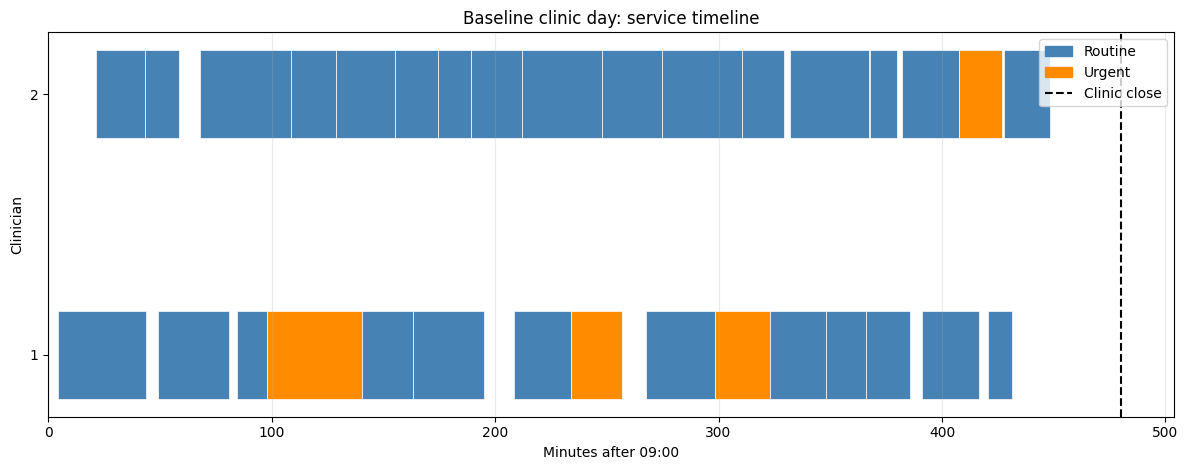

len(baseline_day) = 32 attended scheduled visits plus urgent same-day visits; it is not the number of scheduled appointments or unique appointment requests.


In [8]:
baseline_day = simulate_clinic_day(
    baseline_schedule,
    seed=2026,
    n_clinicians=N_CLINICIANS,
    queue_rule="fcfs",
)

assert (baseline_day["wait_min"] >= 0).all()
assert (baseline_day["service_duration_min"] > 0).all()

# Display the five longest waits.
display(baseline_day.nlargest(5, "wait_min")[[
    "visit_id", "source", "urgency", "arrival_minute",
    "service_start_minute", "completion_minute", "wait_min"
]])

# Clinician timeline; minute 0 = 09:00, minute 480 = 17:00.
fig, ax = plt.subplots(figsize=(12, 4.8))
colors = {"routine": "steelblue", "urgent": "darkorange"}
for _, visit in baseline_day.iterrows():
    ax.barh(
        visit["clinician"],
        visit["service_duration_min"],
        left=visit["service_start_minute"],
        height=0.34,
        color=colors.get(visit["urgency"], "grey"),
        edgecolor="white",
        linewidth=0.5,
    )
ax.axvline(CLINIC_CLOSE_MINUTE, color="black", linestyle="--", label="Clinic close (480 min)")
ax.set(xlabel="Minutes after 09:00", ylabel="Clinician", title="Baseline clinic day: service timeline")
ax.set_yticks(range(1, N_CLINICIANS + 1))
ax.set_xlim(left=0)
ax.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color=colors["routine"], label="Routine"),
    plt.Rectangle((0, 0), 1, 1, color=colors["urgent"], label="Urgent"),
    plt.Line2D([0], [0], color="black", linestyle="--", label="Clinic close"),
], loc="upper right")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print(f"len(baseline_day) = {len(baseline_day)} attended scheduled visits plus urgent same-day visits; it is not the number of scheduled appointments or unique appointment requests.")

## Exercise 3: Calculate operational outcomes — 20 minutes

Implement `summarise_day`. Return a dictionary containing at least:

- `visits`
- `started_by_close`
- `mean_wait_min`
- `median_wait_min`
- `p90_wait_min`
- `max_wait_min`
- `utilization_before_close`
- `overtime_min`
- `urgent_visits`
- `urgent_wait_breaches`

For utilization, count only the part of each consultation falling between minute 0 and minute 480:

$$
\text{busy before close}=
\sum_i \max(0,\min(f_i,480)-\max(s_i,0)),
$$

then divide by `n_clinicians × 480`. Here $s_i$ and $f_i$ are visit $i$'s service start and finish.

In [9]:
def summarise_day(
    visits,
    n_clinicians=N_CLINICIANS,
    closing_minute=CLINIC_CLOSE_MINUTE,
    urgent_wait_review_min=URGENT_WAIT_REVIEW_MIN,
):
    """Summarize access, delay, staffing utilization, overtime, and urgent waits."""
    if visits is None or len(visits) == 0:
        return {
            "visits": 0, "started_by_close": 0, "mean_wait_min": 0.0,
            "median_wait_min": 0.0, "p90_wait_min": 0.0, "max_wait_min": 0.0,
            "utilization_before_close": 0.0, "overtime_min": 0.0,
            "urgent_visits": 0, "urgent_wait_breaches": 0,
        }

    waits = visits["wait_min"].astype(float)
    starts = visits["service_start_minute"].astype(float)
    finishes = visits["completion_minute"].astype(float)
    busy_before_close = np.maximum(
        0.0,
        np.minimum(finishes, closing_minute) - np.maximum(starts, 0.0),
    ).sum()
    started_by_close = int((starts < closing_minute).sum())
    overtime_min = float(np.maximum(finishes - closing_minute, 0.0).max())
    urgent_mask = visits["urgency"].eq("urgent")
    urgent_visits = int(urgent_mask.sum())
    urgent_wait_breaches = int((waits[urgent_mask] > urgent_wait_review_min).sum())

    return {
        "visits": int(len(visits)),
        "started_by_close": started_by_close,
        "mean_wait_min": float(waits.mean()),
        "median_wait_min": float(waits.median()),
        "p90_wait_min": float(waits.quantile(0.90)),
        "max_wait_min": float(waits.max()),
        "utilization_before_close": float(busy_before_close / (n_clinicians * closing_minute)),
        "overtime_min": overtime_min,
        "urgent_visits": urgent_visits,
        "urgent_wait_breaches": urgent_wait_breaches,
    }


baseline_metrics = summarise_day(baseline_day)
display(pd.Series(baseline_metrics, name="baseline_seed_2026"))

visits                      32.000000
started_by_close            32.000000
mean_wait_min                5.491933
median_wait_min              3.026225
p90_wait_min                13.660092
max_wait_min                23.503109
utilization_before_close     0.828948
overtime_min                 0.000000
urgent_visits                4.000000
urgent_wait_breaches         0.000000
Name: baseline_seed_2026, dtype: float64

### Metric checks

Use checks as debugging aids, not as substitutes for interpretation. The utilization definition above should remain between 0 and 1 because it counts only busy time inside the staffed window. Overtime is reported separately.

In [10]:
if baseline_metrics is not None:
    required_metrics = {
        "visits", "started_by_close", "mean_wait_min", "median_wait_min",
        "p90_wait_min", "max_wait_min", "utilization_before_close",
        "overtime_min", "urgent_visits", "urgent_wait_breaches",
    }
    assert required_metrics.issubset(baseline_metrics)
    assert 0 <= baseline_metrics["utilization_before_close"] <= 1
    assert baseline_metrics["mean_wait_min"] <= baseline_metrics["max_wait_min"]
    assert baseline_metrics["urgent_wait_breaches"] <= baseline_metrics["urgent_visits"]
    print("Metric checks passed.")
else:
    print("Metric checks skipped until summarise_day is completed.")

Metric checks passed.


## Exercise 4: Compare scheduling policies — 25 minutes

The candidate policies below change one or more decisions:

- **Baseline:** 30 standard bookings, FCFS.
- **Reserve two:** 28 standard bookings, leaving nominal capacity for same-day demand.
- **Score-guided overbook two:** 30 standard plus two additional requests assigned to high predicted no-show slots.
- **Urgent priority:** baseline bookings with non-preemptive priority for urgent arrivals.

First inspect schedule counts and duplicate slot times. Then run every policy for at least 200 days. Use the same simulation seeds for each policy so that comparisons are not driven merely by different random-number sequences.

In [11]:
policy_definitions = {
    "baseline_fcfs": {
        "schedule": build_schedule(requests),
        "queue_rule": "fcfs",
    },
    "reserve_2_fcfs": {
        "schedule": build_schedule(requests, reserve_slots=2),
        "queue_rule": "fcfs",
    },
    "overbook_2_score_guided": {
        "schedule": build_schedule(
            requests,
            overbook_slots=2,
            score_guided_overbooking=True,
        ),
        "queue_rule": "fcfs",
    },
    "baseline_urgent_priority": {
        "schedule": build_schedule(requests),
        "queue_rule": "urgent_priority",
    },
}

pd.DataFrame(
    [
        {
            "policy": name,
            "scheduled_requests": len(spec["schedule"]),
            "overbooked_requests": (spec["schedule"]["booking_type"] == "overbooked").sum(),
            "queue_rule": spec["queue_rule"],
        }
        for name, spec in policy_definitions.items()
    ]
)

,policy,scheduled_requests,overbooked_requests,queue_rule
0,baseline_fcfs,30,0,fcfs
1,reserve_2_fcfs,28,0,fcfs
2,overbook_2_score_guided,32,2,fcfs
3,baseline_urgent_priority,30,0,urgent_priority


In [12]:
def evaluate_policy(
    policy_name,
    policy_spec,
    seeds,
    urgent_rate=4.0,
    no_show_logit_shift=0.0,
):
    """Evaluate one policy over shared seeds and return one row per simulated day."""
    rows = []
    for simulation_id, seed in enumerate(seeds):
        visits = simulate_clinic_day(
            policy_spec["schedule"],
            seed=int(seed),
            n_clinicians=N_CLINICIANS,
            queue_rule=policy_spec["queue_rule"],
            urgent_rate=urgent_rate,
            no_show_logit_shift=no_show_logit_shift,
        )
        metrics = summarise_day(visits)
        rows.append({
            "policy": policy_name,
            "simulation_id": simulation_id,
            "seed": int(seed),
            **metrics,
        })
    return pd.DataFrame(rows)


# At least 200 days per policy; common random-number seeds improve comparability.
simulation_seeds = np.arange(20_000, 20_300)
policy_results = pd.concat(
    [
        evaluate_policy(name, spec, simulation_seeds)
        for name, spec in policy_definitions.items()
    ],
    ignore_index=True,
)

display(policy_results.head())
print(f"Evaluated {policy_results['policy'].nunique()} policies across {len(simulation_seeds)} shared seeds ({len(policy_results)} policy-days).")

,policy,simulation_id,seed,visits,started_by_close,mean_wait_min,median_wait_min,p90_wait_min,max_wait_min,utilization_before_close,overtime_min,urgent_visits,urgent_wait_breaches
0,baseline_fcfs,0,20000,29,29,15.469978,11.692476,41.693754,50.725742,0.830711,21.238276,4,0
1,baseline_fcfs,1,20001,32,32,45.474626,48.382525,71.871553,79.630140,0.909293,7.837575,5,3
2,baseline_fcfs,2,20002,34,31,47.884402,52.050501,83.488674,92.687510,0.940117,47.131275,6,4
3,baseline_fcfs,3,20003,34,33,31.546786,34.763482,56.888098,62.448676,0.954530,30.023058,7,2
4,baseline_fcfs,4,20004,30,30,6.392889,1.606919,17.131960,30.184471,0.807960,0.000000,2,0


Evaluated 4 policies across 300 shared seeds (1200 policy-days).


Create a policy summary with:

- median visits and started-by-close count;
- median mean wait;
- median and 90th percentile of daily `p90_wait_min`;
- median utilization;
- 90th-percentile overtime; and
- mean urgent-wait breaches.

Then plot at least `mean_wait_min` and `overtime_min` distributions by policy. Explain why reporting only the mean across all simulations would be insufficient.

,policy,median_visits,median_started_by_close,median_mean_wait_min,median_daily_p90_wait_min,p90_daily_p90_wait_min,median_utilization,p90_overtime_min,mean_urgent_wait_breaches
3,reserve_2_fcfs,28.0,28.0,7.774022,21.541991,46.193754,0.776279,9.572292,0.553333
0,baseline_fcfs,30.0,30.0,9.981234,25.606612,53.516733,0.818689,20.929871,0.820000
1,baseline_urgent_priority,30.0,30.0,10.000748,26.576924,60.483114,0.819419,21.002804,0.050000
2,overbook_2_score_guided,32.0,32.0,11.654103,29.026885,61.928565,0.865720,37.132918,0.983333


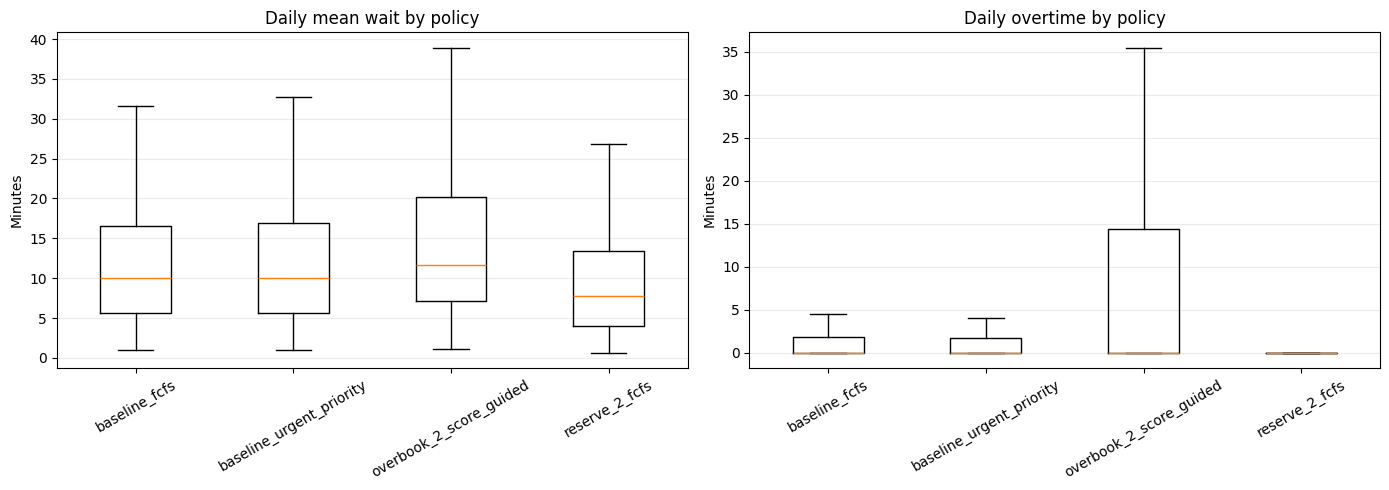

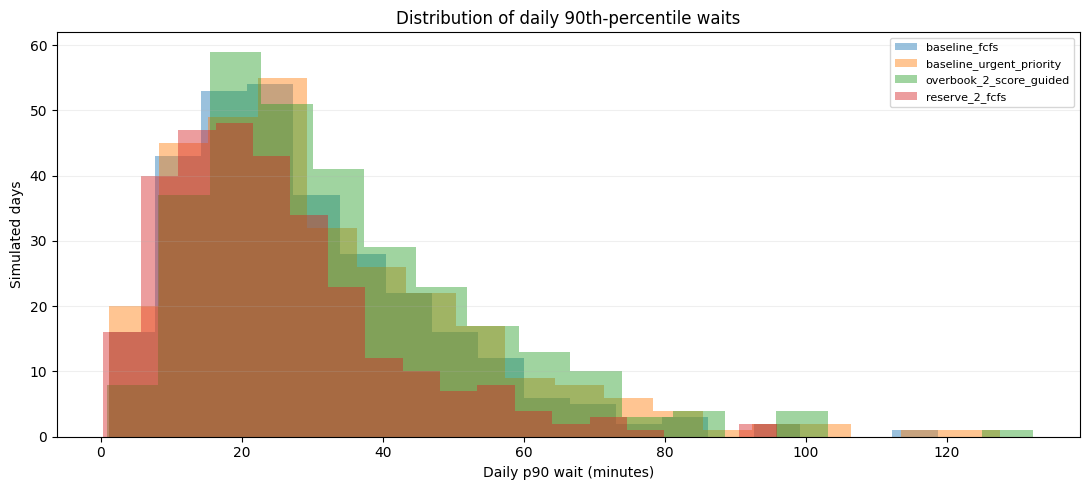

Why the mean alone is insufficient: it can hide rare but severe waiting or overtime days. Medians describe typical days; upper percentiles expose operational tail risk.


In [13]:
# Summarize both typical performance and the high-delay tail.
policy_summary = policy_results.groupby("policy", observed=True).agg(
    median_visits=("visits", "median"),
    median_started_by_close=("started_by_close", "median"),
    median_mean_wait_min=("mean_wait_min", "median"),
    median_daily_p90_wait_min=("p90_wait_min", "median"),
    p90_daily_p90_wait_min=("p90_wait_min", lambda x: x.quantile(0.90)),
    median_utilization=("utilization_before_close", "median"),
    p90_overtime_min=("overtime_min", lambda x: x.quantile(0.90)),
    mean_urgent_wait_breaches=("urgent_wait_breaches", "mean"),
).reset_index()

display(policy_summary.sort_values(["median_mean_wait_min", "p90_overtime_min"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
policy_order = policy_summary.sort_values("policy")["policy"].tolist()
for ax, metric, title in [
    (axes[0], "mean_wait_min", "Daily mean wait by policy"),
    (axes[1], "overtime_min", "Daily overtime by policy"),
]:
    data = [policy_results.loc[policy_results["policy"] == p, metric].to_numpy() for p in policy_order]
    ax.boxplot(data, tick_labels=policy_order, showfliers=False)
    ax.set_title(title)
    ax.set_ylabel("Minutes")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
for policy in policy_order:
    subset = policy_results.loc[policy_results["policy"] == policy, "p90_wait_min"]
    ax.hist(subset, bins=18, alpha=0.45, label=policy)
ax.set(title="Distribution of daily 90th-percentile waits", xlabel="Daily p90 wait (minutes)", ylabel="Simulated days")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print("Why the mean alone is insufficient: it can hide rare but severe waiting or overtime days. Medians describe typical days; upper percentiles expose operational tail risk.")

### Interpretation prompts

1. Which policy completes or starts the most visits before closing?
2. Which policy has the lowest tail waiting and overtime?
3. Does urgent priority improve urgent-delay outcomes? What happens to routine waiting?
4. Does any policy dominate every other policy, or are there trade-offs?
5. Which measures would you treat as constraints rather than components of a weighted score?

### Interpretation of the simulated policy results

- **Most visits:** score-guided overbooking had the highest median visit count (32), versus 30 for baseline and 28 for reserve-two. This throughput gain came with higher waiting and overtime.
- **Lowest typical and tail waiting/overtime:** reserve-two performed best on median mean wait (7.77 min), median daily p90 wait (21.54 min), and p90 overtime (9.57 min), but completed fewer visits.
- **Urgent priority:** it reduced average urgent-wait breaches to 0.05 per day versus 0.82 for baseline FCFS, but the median daily p90 wait and overtime tail were not better. It shifts service order toward urgent arrivals; it does not create extra capacity.
- **No universal winner:** reserve-two favors lower congestion and overtime; urgent priority favors urgent-delay protection; overbooking favors throughput but worsens congestion. These are trade-offs.
- **Constraints, not just weighted-score terms:** urgent-delay escalation, acceptable overtime, access equity, and non-denial of existing appointments should be guardrails. A high visit count should not compensate for unacceptable urgent waits or inequitable access.

The stress tests reinforce the trade-off. With urgent demand increased to 7/day, reserve-two had the lowest median mean wait (15.30 min) and p90 overtime (43.26 min), while urgent priority had the fewest urgent-wait breaches (0.20/day). Under attendance drift, reserve-two again had the lowest median mean wait (8.83 min) and p90 overtime (15.37 min). These results are generated under assumed distributions and do not establish real-world performance.

## Exercise 5: Stress-test assumptions — 15 minutes

Policies should not be selected using only one assumed future. Repeat the policy comparison under:

1. **Demand surge:** set `urgent_rate=7.0`.
2. **Attendance drift:** set `no_show_logit_shift=-0.6`. This makes actual non-attendance less likely than the unchanged predictions suggest.

Store the two summaries as `surge_summary` and `attendance_drift_summary`. Identify any policy whose apparent advantage disappears or whose safety/workload outcomes worsen materially.

Explain why this is a policy stress test rather than external clinical validation.

In [14]:
# Stress test 1: more urgent same-day demand.
surge_results = pd.concat(
    [
        evaluate_policy(name, spec, simulation_seeds, urgent_rate=7.0)
        for name, spec in policy_definitions.items()
    ],
    ignore_index=True,
)
surge_summary = surge_results.groupby("policy", observed=True).agg(
    median_visits=("visits", "median"),
    median_mean_wait_min=("mean_wait_min", "median"),
    p90_daily_p90_wait_min=("p90_wait_min", lambda x: x.quantile(0.90)),
    p90_overtime_min=("overtime_min", lambda x: x.quantile(0.90)),
    mean_urgent_wait_breaches=("urgent_wait_breaches", "mean"),
).reset_index()

# Stress test 2: attendance is higher than predicted (negative logit shift).
attendance_drift_results = pd.concat(
    [
        evaluate_policy(name, spec, simulation_seeds, no_show_logit_shift=-0.6)
        for name, spec in policy_definitions.items()
    ],
    ignore_index=True,
)
attendance_drift_summary = attendance_drift_results.groupby("policy", observed=True).agg(
    median_visits=("visits", "median"),
    median_mean_wait_min=("mean_wait_min", "median"),
    p90_daily_p90_wait_min=("p90_wait_min", lambda x: x.quantile(0.90)),
    p90_overtime_min=("overtime_min", lambda x: x.quantile(0.90)),
    mean_urgent_wait_breaches=("urgent_wait_breaches", "mean"),
).reset_index()

print("Demand-surge summary (urgent_rate=7):")
display(surge_summary)
print("Attendance-drift summary (no_show_logit_shift=-0.6):")
display(attendance_drift_summary)
print("These are assumption stress tests within a synthetic model, not external clinical validation.")

Demand-surge summary (urgent_rate=7):


,policy,median_visits,median_mean_wait_min,p90_daily_p90_wait_min,p90_overtime_min,mean_urgent_wait_breaches
0,baseline_fcfs,33.0,19.609399,86.651230,62.899277,2.666667
1,baseline_urgent_priority,33.0,20.548667,105.620245,60.176689,0.196667
2,overbook_2_score_guided,35.0,23.254914,96.139306,80.924624,3.143333
3,reserve_2_fcfs,31.0,15.300876,74.124415,43.262556,2.083333


Attendance-drift summary (no_show_logit_shift=-0.6):


,policy,median_visits,median_mean_wait_min,p90_daily_p90_wait_min,p90_overtime_min,mean_urgent_wait_breaches
0,baseline_fcfs,32.0,11.623561,61.209354,31.284973,0.903333
1,baseline_urgent_priority,32.0,11.616436,69.230294,30.685636,0.056667
2,overbook_2_score_guided,33.0,15.080618,67.548704,44.011053,1.213333
3,reserve_2_fcfs,30.0,8.831535,49.948149,15.366944,0.656667


These are assumption stress tests within a synthetic model, not external clinical validation.


## Exercise 6: Audit subgroup effects — 15 minutes

The score partly reflects travel time, so score-guided overbooking may affect the two synthetic access groups differently.

For the score-guided policy:

1. Count standard and overbooked requests by `access_group`.
2. Across at least 200 simulated days, calculate attended sample size, mean wait, and 90th-percentile wait by group.
3. Compare those results with the baseline.
4. Report sample sizes beside every subgroup measure.
5. Explain why an observed difference is a reason to investigate, not proof of discrimination or harm.

Do not treat missing `access_group` for synthetic urgent arrivals as one of the scheduled-patient groups.

In [15]:
# Booking allocation audit: scheduled patients only, separated by policy and access group.
booking_frames = []
for policy_name, policy_spec in policy_definitions.items():
    schedule = policy_spec["schedule"].copy()
    audit = schedule.groupby(["access_group", "booking_type"], observed=True).agg(
        request_count=("request_id", "count"),
        mean_predicted_no_show_probability=("predicted_no_show_probability", "mean"),
        mean_travel_minutes=("travel_minutes", "mean"),
    ).reset_index()
    audit.insert(0, "policy", policy_name)
    booking_frames.append(audit)
booking_audit_by_group = pd.concat(booking_frames, ignore_index=True)

# Repeated-day outcomes by scheduled-patient access group; urgent synthetic arrivals are excluded.
subgroup_frames = []
for policy_name in ["baseline_fcfs", "overbook_2_score_guided"]:
    schedule = policy_definitions[policy_name]["schedule"]
    for seed in simulation_seeds:
        visits = simulate_clinic_day(
            schedule,
            seed=int(seed),
            n_clinicians=N_CLINICIANS,
            queue_rule=policy_definitions[policy_name]["queue_rule"],
        )
        scheduled_visits = visits.loc[visits["source"].eq("scheduled")].copy()
        for group, group_visits in scheduled_visits.groupby("access_group", observed=True):
            subgroup_frames.append({
                "policy": policy_name,
                "seed": int(seed),
                "access_group": group,
                "attended_n": int(len(group_visits)),
                "mean_wait_min": float(group_visits["wait_min"].mean()),
                "p90_wait_min": float(group_visits["wait_min"].quantile(0.90)),
            })
subgroup_day_results = pd.DataFrame(subgroup_frames)
subgroup_results = subgroup_day_results.groupby(["policy", "access_group"], observed=True).agg(
    simulated_days=("seed", "nunique"),
    total_attended_visits=("attended_n", "sum"),
    mean_attended_n_per_day=("attended_n", "mean"),
    mean_wait_min=("mean_wait_min", "mean"),
    median_daily_mean_wait_min=("mean_wait_min", "median"),
    p90_daily_p90_wait_min=("p90_wait_min", lambda x: x.quantile(0.90)),
).reset_index()

display(booking_audit_by_group)
display(subgroup_results)
print("Subgroup estimates are descriptive synthetic results. Always read the sample sizes with the wait measures; differences are signals to investigate, not proof of discrimination or harm.")

,policy,access_group,booking_type,request_count,mean_predicted_no_show_probability,mean_travel_minutes
0,baseline_fcfs,far_from_clinic,standard,9,0.208641,63.666667
1,baseline_fcfs,near_clinic,standard,21,0.090063,16.809524
2,reserve_2_fcfs,far_from_clinic,standard,9,0.208641,63.666667
3,reserve_2_fcfs,near_clinic,standard,19,0.091568,16.842105
4,overbook_2_score_guided,far_from_clinic,standard,9,0.208641,63.666667
5,overbook_2_score_guided,near_clinic,overbooked,2,0.098647,9.000000
6,overbook_2_score_guided,near_clinic,standard,21,0.090063,16.809524
7,baseline_urgent_priority,far_from_clinic,standard,9,0.208641,63.666667
8,baseline_urgent_priority,near_clinic,standard,21,0.090063,16.809524


,policy,access_group,simulated_days,total_attended_visits,mean_attended_n_per_day,mean_wait_min,median_daily_mean_wait_min,p90_daily_p90_wait_min
0,baseline_fcfs,far_from_clinic,300,2149,7.163333,10.903531,7.806821,48.129097
1,baseline_fcfs,near_clinic,300,5710,19.033333,13.641322,10.197771,55.305310
2,overbook_2_score_guided,far_from_clinic,300,2118,7.060000,13.624508,10.134204,53.747991
3,overbook_2_score_guided,near_clinic,300,6252,20.840000,16.195907,11.752669,60.745867


Subgroup estimates are descriptive synthetic results. Always read the sample sizes with the wait measures; differences are signals to investigate, not proof of discrimination or harm.


## Exercise 7: Recommendation memo — 10 minutes

**Recommendation memo (based on the 300-day synthetic simulations):**

Dear Clinic Manager,

I do not recommend selecting a single policy for operational deployment from this simulation alone. The reserve-two policy produced the lowest median daily mean wait (7.77 minutes), lowest median daily 90th-percentile wait (21.54 minutes), and lowest 90th-percentile overtime (9.57 minutes), but it also had the fewest visits (median 28). Score-guided overbooking increased median visits to 32 and median utilization to 0.866, but increased median mean wait to 11.65 minutes and 90th-percentile overtime to 37.13 minutes. Urgent-priority queuing reduced mean urgent-wait breaches from 0.82 per day under baseline FCFS to 0.05, but did not improve routine/tail waiting and still showed substantial overtime risk.

Under a demand surge, the reserve-two policy retained the lowest median mean wait (15.30 minutes) and lowest 90th-percentile overtime (43.26 minutes), while urgent priority had the fewest urgent-wait breaches (0.20 per day). When attendance was higher than predicted, reserve-two again had the lowest median mean wait (8.83 minutes) and overtime tail (15.37 minutes). The subgroup audit also warrants review: under score-guided overbooking, far-from-clinic patients had 2,118 attended visits across 300 days versus 2,149 at baseline, while near-clinic attendance increased; these are descriptive synthetic counts, not proof of harm.

Keep the current process as the control and test any change only in a staff-supervised, reversible pilot with clinician override and established urgent escalation. Monitor urgent waits over 30 minutes, daily 90th-percentile waiting, and overtime alongside completed visits. The model omits rooms, breaks, acuity, staff absences, and patient choice, so it is not clinical validation.

Sincerely,  
Charan.




## Reflection questions

1. Why can average daily workload be below nominal capacity while patients still wait?
Even if the clinic has enough capacity for the whole day, many patients may arrive at the same time. This creates queues and increases waiting time.
2. What information was available at scheduling time, and what was realized later?
At scheduling time, we know the predicted no-show probability, travel time, and planned schedule. Later, we find out who actually attends, consultation duration, and when urgent cases arrive.
3. Why might optimizing only utilization produce an undesirable policy?
High utilization keeps clinicians busy, but patients may have to wait longer. It can also increase overtime and delay urgent patients.
4. How does non-preemptive urgent priority differ from interrupting a consultation?
Non-preemptive priority means urgent patients are seen when a clinician becomes free. Interrupting means stopping an ongoing consultation to treat an urgent patient immediately.
5. What operational features are absent from this simulation, and which omission matters most?
The simulation does not fully consider rooms, staff breaks, equipment, and different staff roles. Room and staff availability are important because a clinician cannot always treat a patient just because they are free.
6. How would deployment change the future data used to retrain a no-show model?
The new scheduling policy may change patient attendance behaviour. Therefore, future data may differ from old data, so the model must be checked and retrained when necessary.
7. What evidence would be required before applying this approach in a real clinic?
We need to test the approach using real clinic data and compare it with the current scheduling system. We should also check waiting times, urgent cases, patient safety, fairness, and clinician workload before using it in practice



